# Experiment 0: auxiliary experiment checks

Fast functional checks for experiments 2 and 3. These short runs verify seeds, disjoint sampling, averaged-gradient updates, checkpoint recovery and evaluation. They do not measure research performance or certify large-table memory limits.

These controls establish execution and measurement validity. They do not test whether credit-domain specialization improves generalization.


## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('experiment0/04_auxiliary_experiments')
report = cp.NotebookReport('Experiment 0: auxiliary experiment checks', sink=sink)

print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'These controls establish execution and measurement validity. They do not test whether credit-domain specialization improves generalization.')
from src.visualize import auxiliary as aux

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Planned checks

Eight GPU tasks cover TabPFN v2, TabPFN v2.6, TabPFN v3 and TabICL v2 on both tracks. Each task executes its short cases sequentially. Two small adaptation tables and one held-out table preserve their roles in dataset partition zero. TabICLv2 uses its own native objective. The fixed reference uses full updates, peak LR 3e-7 and L2-SP 0.003.

In [2]:
report.table('Planned auxiliary cases', aux.planned_checks())
report.add('1. Planned checks', '52 six-update arms across eight GPU tasks: 36 uninterrupted arms and 16 interrupted/resumed comparisons. LGD seed-42 one-sample also serves as the stratified sampling control. PD has a separate stratified control. The tiny 256-row cap and smoke retention panel bound debugging cost.')

,track,case,bases,updates,interrupt_after,row_cap,purpose
0,PD,seed42,4,6,NaN,256,Seed sensitivity
1,PD,seed43,4,6,NaN,256,Seed sensitivity
2,PD,one_sample,4,6,NaN,256,Sampling execution
3,PD,full_pass,4,6,NaN,256,Sampling execution
4,PD,accumulate,4,6,NaN,256,Sampling execution
5,PD,full_pass_resumed,4,6,3.0,256,Resume equivalence
6,PD,accumulate_resumed,4,6,3.0,256,Resume equivalence
7,LGD,seed42,4,6,NaN,256,Seed sensitivity
8,LGD,seed43,4,6,NaN,256,Seed sensitivity
9,LGD,full_pass,4,6,NaN,256,Sampling execution


## 2. Seed and recovery evidence

Seed 43 must change trained weights while preserving fixed update-zero monitors. Each full-pass and accumulation continuation must match its uninterrupted reference in weights, monitor values and row exposure. A failed, absent or pending task is not a pass.

In [3]:
scope, checks, arms = aux.evidence()
print(scope)
report.table('Per-task functional checks', checks)
report.add('2. Seed and recovery evidence', str(scope))

{'workflow': 'cc862607c5a24ca0940b4e1eb9a239a9', 'status': 'passed', 'reported_tasks': 8, 'expected_tasks': 8, 'fingerprint': '5c355dfc6ca022ff870dcb349772808b8ac01af3cc950195d48483b41a07db8e'}


,track,base,passed,initial_monitor_equal,seed_weights_differ,full_pass_recovery,accumulate_recovery,exposure_check,five_fold_benchmark
0,LGD,TabPFN v2,True,True,True,True,True,True,True
1,LGD,TabPFN v2.6,True,True,True,True,True,True,True
2,LGD,TabPFN v3,True,True,True,True,True,True,True
3,LGD,TabICLv2,True,True,True,True,True,True,True
4,PD,TabPFN v2,True,True,True,True,True,True,True
5,PD,TabPFN v2.6,True,True,True,True,True,True,True
6,PD,TabPFN v3,True,True,True,True,True,True,True
7,PD,TabICLv2,True,True,True,True,True,True,True


## 3. Budget, sampling and evaluation

Full pass updates after each chunk; accumulation averages chunk gradients and updates once per table. Both traverse disjoint rows and repartition next epoch. The reloaded seed-43 checkpoint also undergoes five-fold package-data evaluation with inner-validation threshold or calibration fitting.

In [4]:
report.table('Recorded arms and processed row exposures', arms)
report.add('3. Budget, sampling and evaluation', 'Equal successful-update counts do not imply equal row exposure or GPU cost. Functional success requires all eight task reports and the CPU audit receipt. The workflow never automatically starts a research experiment.')

,track,base,case,seed,sampling,context_sampling,trial,updates,processed_rows
0,LGD,TabPFN v2,seed42,42,one_sample,stratified,cpt_pilot_aux_cc862607c5a2_seed42_s00_lgd_tabp...,6,1536
1,LGD,TabPFN v2,seed43,43,one_sample,stratified,cpt_pilot_aux_cc862607c5a2_seed43_s00_lgd_tabp...,6,1536
2,LGD,TabPFN v2,full_pass,42,full_pass,stratified,cpt_pilot_aux_cc862607c5a2_full_pass_s00_lgd_t...,6,1280
3,LGD,TabPFN v2,accumulate,42,accumulate,stratified,cpt_pilot_aux_cc862607c5a2_accumulate_s00_lgd_...,6,3840
4,LGD,TabPFN v2,full_pass_resumed,42,full_pass,stratified,cpt_pilot_aux_cc862607c5a2_full_pass_resumed_s...,6,1280
5,LGD,TabPFN v2,accumulate_resumed,42,accumulate,stratified,cpt_pilot_aux_cc862607c5a2_accumulate_resumed_...,6,3840
6,LGD,TabPFN v2.6,seed42,42,one_sample,stratified,cpt_pilot_aux_cc862607c5a2_seed42_s00_lgd_tabp...,6,1536
7,LGD,TabPFN v2.6,seed43,43,one_sample,stratified,cpt_pilot_aux_cc862607c5a2_seed43_s00_lgd_tabp...,6,1536
8,LGD,TabPFN v2.6,full_pass,42,full_pass,stratified,cpt_pilot_aux_cc862607c5a2_full_pass_s00_lgd_t...,6,1280
9,LGD,TabPFN v2.6,accumulate,42,accumulate,stratified,cpt_pilot_aux_cc862607c5a2_accumulate_s00_lgd_...,6,3840


## 4. Final inference checks

A separate checkpoint-only diagnostic checks TabICL numerical settings and unchanged-save parity before interpreting its CPT gains. Earlier experiment-0 receipts remain separate. Original/saved/CPT AUC is shown above a direct CPT-minus-original comparison under each numerical policy. The five paired fold contrasts are descriptive; these three post-hoc tables cannot estimate how common precision sensitivity is.

,task,dataset,fold,status,project_journals_audited
0,0,Vehicle Loan,0,passed,True
1,1,Vehicle Loan,1,passed,True
2,2,Vehicle Loan,2,passed,True
3,3,Vehicle Loan,3,passed,True
4,4,Vehicle Loan,4,passed,True
5,5,Myhom,0,passed,True
6,6,Myhom,1,passed,True
7,7,Myhom,2,passed,True
8,8,Myhom,3,passed,True
9,9,Myhom,4,passed,True


,task,dataset,fold,roc_auc,brier_score,resolved_amp,resolved_fa3,actual_attention,seconds,peak_allocated_bytes,...,float32_matmul_precision,gpu,cuda_runtime,context_sha256,test_sha256,test_rows,context_rows,scope,policy,state
0,0,Vehicle Loan,0,0.576335,0.281713,True,True,{'torch_SDPA_dispatch/torch.float16/cuda': 258},47.692003,95322249728,...,highest,NVIDIA B200,13.0,f436e745f7cbacf83c86b5c021b4d313d82c424c4f768b...,53837b25ed2c786b1b84a2fa17c0462bbe93355741ad3f...,46631,149218,benchmark,auto,base
1,0,Vehicle Loan,0,0.650424,0.162362,True,True,{'torch_SDPA_dispatch/torch.float16/cuda': 258},24.210605,95322249728,...,highest,NVIDIA B200,13.0,f436e745f7cbacf83c86b5c021b4d313d82c424c4f768b...,53837b25ed2c786b1b84a2fa17c0462bbe93355741ad3f...,46631,149218,benchmark,auto,cpt
2,0,Vehicle Loan,0,0.576335,0.281713,True,True,{'torch_SDPA_dispatch/torch.float16/cuda': 258},24.086068,95322249728,...,highest,NVIDIA B200,13.0,f436e745f7cbacf83c86b5c021b4d313d82c424c4f768b...,53837b25ed2c786b1b84a2fa17c0462bbe93355741ad3f...,46631,149218,benchmark,auto,saved
3,0,Vehicle Loan,0,0.652398,0.162038,False,False,{'torch_SDPA_dispatch/torch.float32/cuda': 258},241.509963,160338786816,...,highest,NVIDIA B200,13.0,f436e745f7cbacf83c86b5c021b4d313d82c424c4f768b...,53837b25ed2c786b1b84a2fa17c0462bbe93355741ad3f...,46631,149218,benchmark,fp32_no_fa3,base
4,0,Vehicle Loan,0,0.650489,0.162359,False,False,{'torch_SDPA_dispatch/torch.float32/cuda': 258},241.263142,160338786816,...,highest,NVIDIA B200,13.0,f436e745f7cbacf83c86b5c021b4d313d82c424c4f768b...,53837b25ed2c786b1b84a2fa17c0462bbe93355741ad3f...,46631,149218,benchmark,fp32_no_fa3,cpt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,14,Taiwan Credit Card,4,0.781623,0.135918,True,True,{'torch_SDPA_dispatch/torch.float16/cuda': 102},1.565533,9094920192,...,highest,NVIDIA B200,13.0,bd0eabc4762340695b67a37dbd4035e51e81dd0961bf94...,4c2c5e1b053128a7848974dcaa5136f5a263f4d92dd7c1...,6000,19200,benchmark,auto,cpt
110,14,Taiwan Credit Card,4,0.782934,0.135452,True,True,{'torch_SDPA_dispatch/torch.float16/cuda': 102},1.615081,9094920192,...,highest,NVIDIA B200,13.0,bd0eabc4762340695b67a37dbd4035e51e81dd0961bf94...,4c2c5e1b053128a7848974dcaa5136f5a263f4d92dd7c1...,6000,19200,benchmark,auto,saved
111,14,Taiwan Credit Card,4,0.782735,0.135511,False,False,{'torch_SDPA_dispatch/torch.float32/cuda': 102},6.296221,15200188416,...,highest,NVIDIA B200,13.0,bd0eabc4762340695b67a37dbd4035e51e81dd0961bf94...,4c2c5e1b053128a7848974dcaa5136f5a263f4d92dd7c1...,6000,19200,benchmark,fp32_no_fa3,base
112,14,Taiwan Credit Card,4,0.781610,0.135920,False,False,{'torch_SDPA_dispatch/torch.float32/cuda': 102},6.171633,15200188416,...,highest,NVIDIA B200,13.0,bd0eabc4762340695b67a37dbd4035e51e81dd0961bf94...,4c2c5e1b053128a7848974dcaa5136f5a263f4d92dd7c1...,6000,19200,benchmark,fp32_no_fa3,cpt


,task,dataset,fold,roc_auc,brier_score,resolved_amp,resolved_fa3,actual_attention,seconds,peak_allocated_bytes,...,float32_matmul_precision,gpu,cuda_runtime,context_sha256,test_sha256,test_rows,context_rows,scope,policy,state
6,0,Vehicle Loan,0,0.480642,0.188143,True,False,{'torch_SDPA_dispatch/torch.float16/cuda': 84},0.805408,789591552,...,highest,NVIDIA B200,13.0,a4aecb0c049e3ba6d5d192e3a5f143136863a1aabf0e4c...,bfb83b89077186b3935769ba3e8fb371fcae0071e2ab5c...,256,1023,boundary,amp_no_fa3,base
7,0,Vehicle Loan,0,0.604432,0.165825,True,False,{'torch_SDPA_dispatch/torch.float16/cuda': 84},0.262299,789591552,...,highest,NVIDIA B200,13.0,a4aecb0c049e3ba6d5d192e3a5f143136863a1aabf0e4c...,bfb83b89077186b3935769ba3e8fb371fcae0071e2ab5c...,256,1023,boundary,amp_no_fa3,cpt
8,0,Vehicle Loan,0,0.601266,0.165814,False,False,{'torch_SDPA_dispatch/torch.float32/cuda': 84},0.367017,1217107456,...,highest,NVIDIA B200,13.0,a4aecb0c049e3ba6d5d192e3a5f143136863a1aabf0e4c...,bfb83b89077186b3935769ba3e8fb371fcae0071e2ab5c...,256,1023,boundary,auto,base
9,0,Vehicle Loan,0,0.604342,0.165781,False,False,{'torch_SDPA_dispatch/torch.float32/cuda': 84},0.349640,1217107456,...,highest,NVIDIA B200,13.0,a4aecb0c049e3ba6d5d192e3a5f143136863a1aabf0e4c...,bfb83b89077186b3935769ba3e8fb371fcae0071e2ab5c...,256,1023,boundary,auto,cpt
10,0,Vehicle Loan,0,0.601266,0.165814,False,False,{'torch_SDPA_dispatch/torch.float32/cuda': 84},0.350566,1217107456,...,highest,NVIDIA B200,13.0,a4aecb0c049e3ba6d5d192e3a5f143136863a1aabf0e4c...,bfb83b89077186b3935769ba3e8fb371fcae0071e2ab5c...,256,1023,boundary,fp32_no_fa3,base
11,0,Vehicle Loan,0,0.604342,0.165781,False,False,{'torch_SDPA_dispatch/torch.float32/cuda': 84},0.403304,1217107456,...,highest,NVIDIA B200,13.0,a4aecb0c049e3ba6d5d192e3a5f143136863a1aabf0e4c...,bfb83b89077186b3935769ba3e8fb371fcae0071e2ab5c...,256,1023,boundary,fp32_no_fa3,cpt
12,0,Vehicle Loan,0,0.596201,0.210087,True,False,{'torch_SDPA_dispatch/torch.float16/cuda': 84},0.861721,5351082496,...,highest,NVIDIA B200,13.0,f0d5a66ccdb31895892a4e5d9710175b2e680fcf19a729...,bfb83b89077186b3935769ba3e8fb371fcae0071e2ab5c...,256,10239,boundary,amp_no_fa3,base
13,0,Vehicle Loan,0,0.654319,0.161284,True,False,{'torch_SDPA_dispatch/torch.float16/cuda': 84},0.941333,5351082496,...,highest,NVIDIA B200,13.0,f0d5a66ccdb31895892a4e5d9710175b2e680fcf19a729...,bfb83b89077186b3935769ba3e8fb371fcae0071e2ab5c...,256,10239,boundary,amp_no_fa3,cpt
14,0,Vehicle Loan,0,0.596201,0.210087,True,False,{'torch_SDPA_dispatch/torch.float16/cuda': 84},0.956092,5351082496,...,highest,NVIDIA B200,13.0,f0d5a66ccdb31895892a4e5d9710175b2e680fcf19a729...,bfb83b89077186b3935769ba3e8fb371fcae0071e2ab5c...,256,10239,boundary,auto,base
15,0,Vehicle Loan,0,0.654319,0.161284,True,False,{'torch_SDPA_dispatch/torch.float16/cuda': 84},0.864182,5351082496,...,highest,NVIDIA B200,13.0,f0d5a66ccdb31895892a4e5d9710175b2e680fcf19a729...,bfb83b89077186b3935769ba3e8fb371fcae0071e2ab5c...,256,10239,boundary,auto,cpt


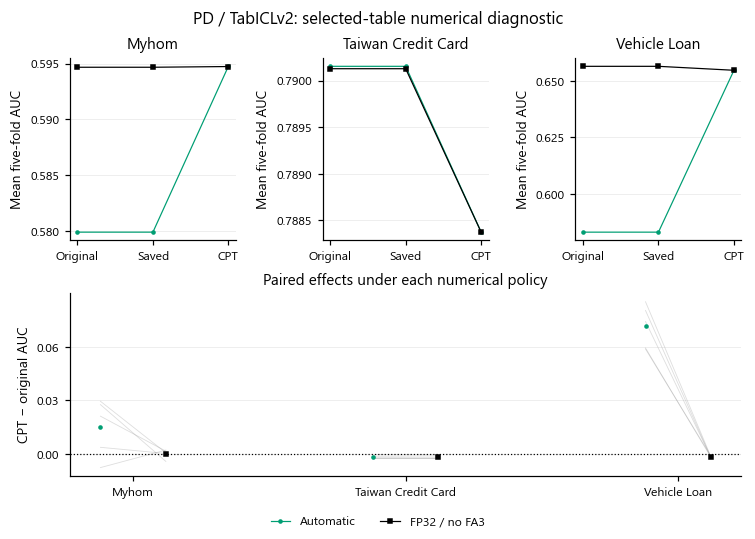

PD. TabICL five-fold AUC under automatic numerical settings and FP32 tensors with Flash Attention 3 disabled. The saved control writes unchanged original weights through the CPT serialization path. Contexts, preprocessing, inference views and test rows match between states and policies. The lower panel subtracts original from CPT AUC within policy and fold. Thin gray segments connect each of five paired fold effects; colored markers show their mean, not a confidence interval. The three post-hoc diagnostic tables were chosen to investigate observed numerical sensitivity and do not estimate its prevalence across credit tasks. Boundary probes are excluded from this figure.

In [5]:
from src.visualize import inference_review as review
review_coverage, review_values, review_boundaries = review.evidence()
report.table('Numerical-review completion and parity', review_coverage)
report.table('Native-context five-fold measurements', review_values)
report.table('Fixed-query boundary probes', review_boundaries)
cp.show(sink, review.plot(review_coverage, review_values), track="pd")
report.add('4. Final inference checks', review.NOTE)


## Complete text summary

In [6]:
print(report.summary(sink))

Experiment 0: auxiliary experiment checks

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
These controls establish execution and measurement validity. They do not test whether credit-domain specialization improves generalization.

1. Planned checks
52 six-update arms across eight GPU tasks: 36 uninterrupted arms and 16 interrupted/resumed comparisons. LGD seed-42 one-sample also serves as the stratified sampling control. PD has a separate stratified control. The tiny 256-row cap and smoke retention panel bound debugging cost.

Table: Planned auxiliary cases
CSV (first column: row index)
row,track,case,bases,updates,interrupt_after,row_cap,purpose
0,PD,seed42,4,6,unavailable,256,Seed sensitivity
1,PD,seed43,4,6,unavailable,256,Seed sensitivity
2,PD,one_sample,4,6,unavailable,256,Sampling execution
3,PD,full_pass,4,6,unavailable,256,Sampling execution
4,P